---
# Final Project (House Price Prediction)
---

In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [95]:
df = pd.read_csv("house_price_prediction.csv")
df.head()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


In [96]:
print("Dataset shape:", df.shape)

Dataset shape: (1000, 8)


In [97]:
print("Data types of each column:")
df.dtypes

Data types of each column:


Square_Footage            int64
Num_Bedrooms              int64
Num_Bathrooms             int64
Year_Built                int64
Lot_Size                float64
Garage_Size               int64
Neighborhood_Quality      int64
House_Price             float64
dtype: object

In [98]:
print("Statistical summary:")
df.describe()

Statistical summary:


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


In [99]:
print("Missing values in each column:")
df.isnull().sum()

Missing values in each column:


Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64

In [100]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


---
### Data Cleaning and Preprocessing
---

In [101]:
df_clean = df.copy()

In [102]:
df_clean.head()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


In [103]:
numeric_cols = [
    "Square_Footage",
    "Num_Bedrooms",
    "Num_Bathrooms",
    "Lot_Size",
    "Garage_Size",
    "Neighborhood_Quality"
]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

In [104]:
for col in ["Square_Footage", "Num_Bedrooms", "Num_Bathrooms", "Lot_Size"]:
    df_clean.loc[
        (df_clean[col] <= 0),
        col
    ] = np.nan

for col in ["Garage_Size", "Neighborhood_Quality"]:
    df_clean.loc[df_clean[col] < 0, col] = np.nan

In [105]:
import datetime

current_year = datetime.datetime.now().year
df_clean.loc[
    (df_clean["Year_Built"] <= 1600) | (df_clean["Year_Built"] > current_year), 
    "Year_Built"
] = np.nan

In [106]:
for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

df_clean['Year_Built'] = df_clean["Year_Built"].fillna(df_clean["Year_Built"].mode())

In [107]:
print("Missing values after cleaning:")
print(df_clean.isnull().sum())
print("\nDuplicate rows:", df_clean.duplicated().sum())
print("\nCleaned dataset shape:", df_clean.shape)

Missing values after cleaning:
Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64

Duplicate rows: 0

Cleaned dataset shape: (1000, 8)


---
### Detect Outliers
---

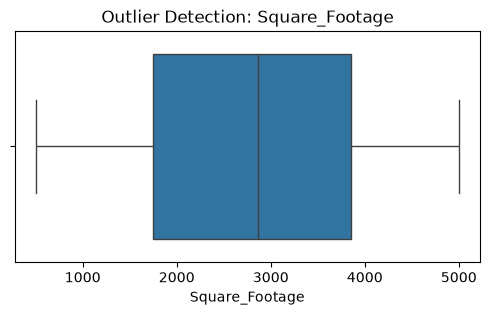

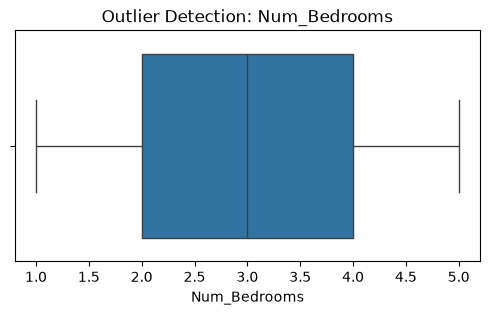

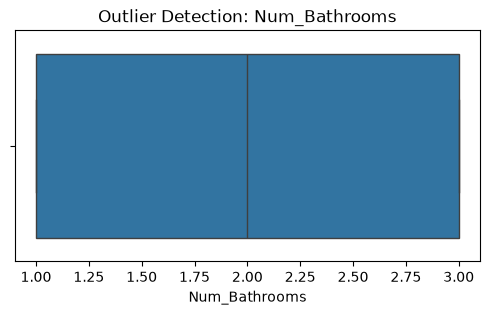

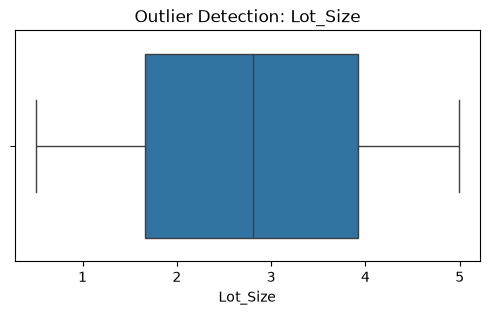

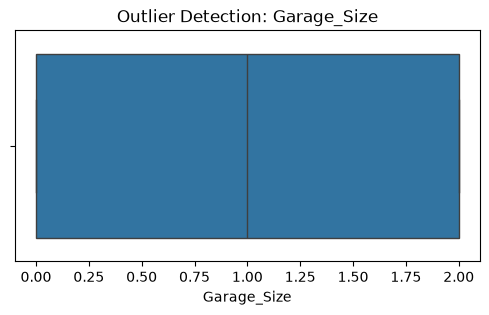

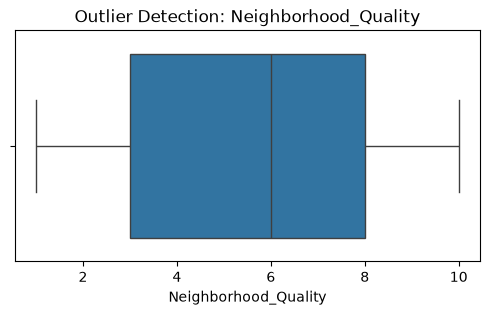

In [108]:
for col in numeric_cols:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df_clean[col])
    plt.title(f"Outlier Detection: {col}")
    plt.show()

In [109]:
for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df_clean[col] < lower_limit) |
        (df_clean[col] > upper_limit)
    ]

    print(f"\nColumn: {col}")
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Number of outliers:", len(outliers))

    display(outliers)


Column: Square_Footage
Lower limit: -1400.5
Upper limit: 6999.5
Number of outliers: 0


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price



Column: Num_Bedrooms
Lower limit: -1.0
Upper limit: 7.0
Number of outliers: 0


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price



Column: Num_Bathrooms
Lower limit: -2.0
Upper limit: 6.0
Number of outliers: 0


...

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price



Column: Garage_Size
Lower limit: -3.0
Upper limit: 5.0
Number of outliers: 0


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price



Column: Neighborhood_Quality
Lower limit: -4.5
Upper limit: 15.5
Number of outliers: 0


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price


---
### Analyze Relationships And Correlations
---

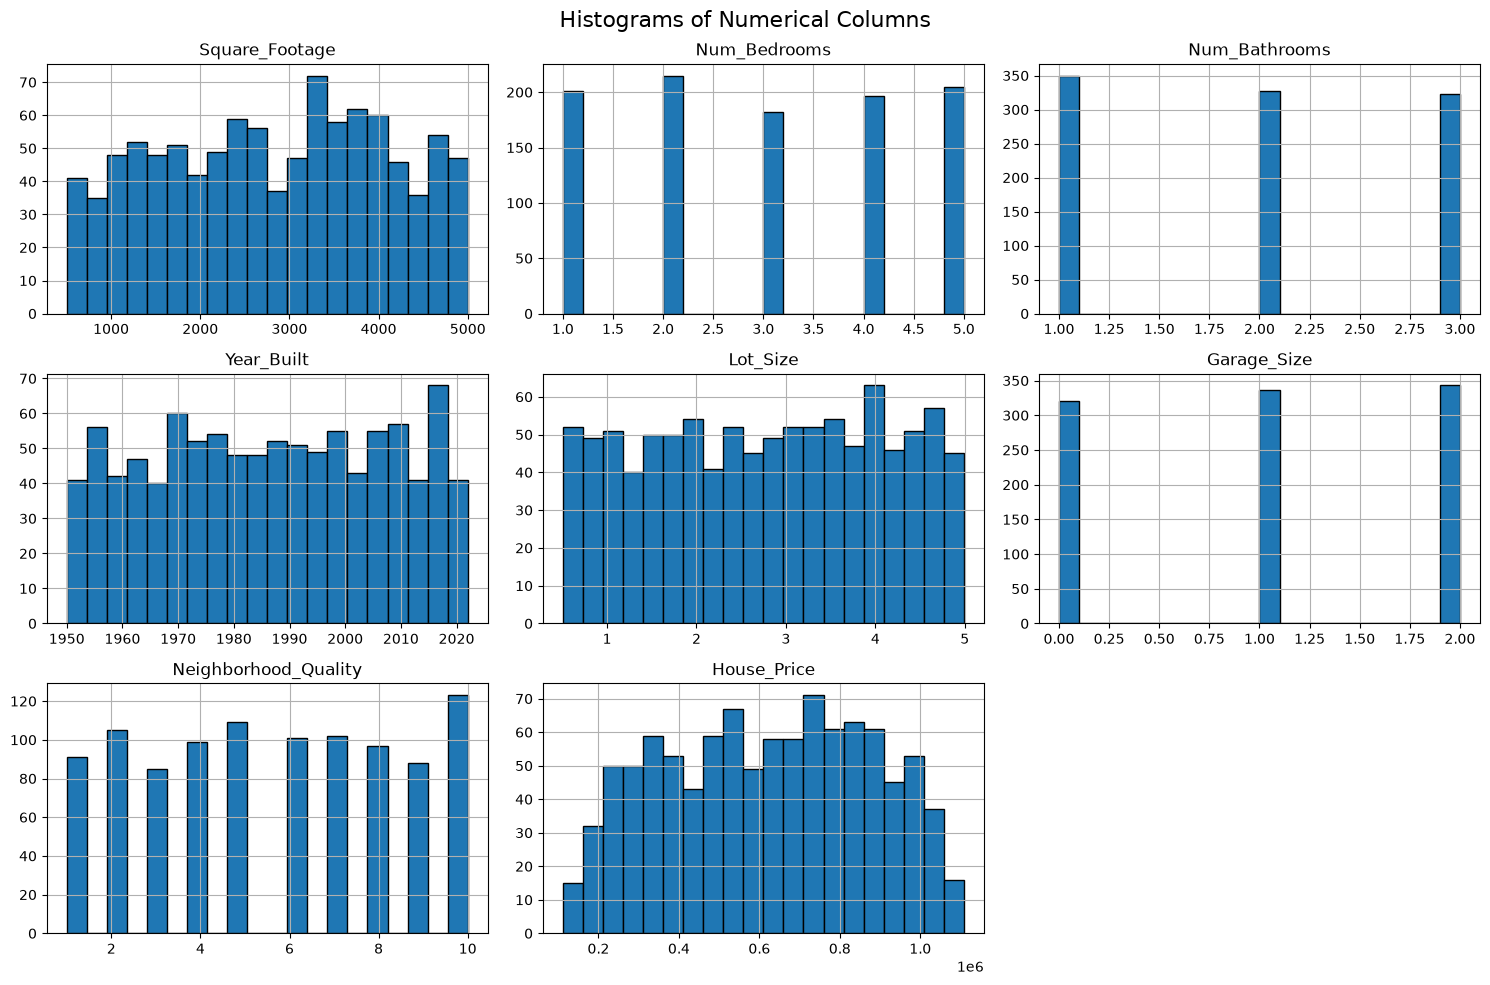

In [110]:
df_clean.hist(bins=20, figsize=(15, 10), edgecolor="black")

plt.suptitle("Histograms of Numerical Columns", fontsize=16)
plt.tight_layout()
plt.show()

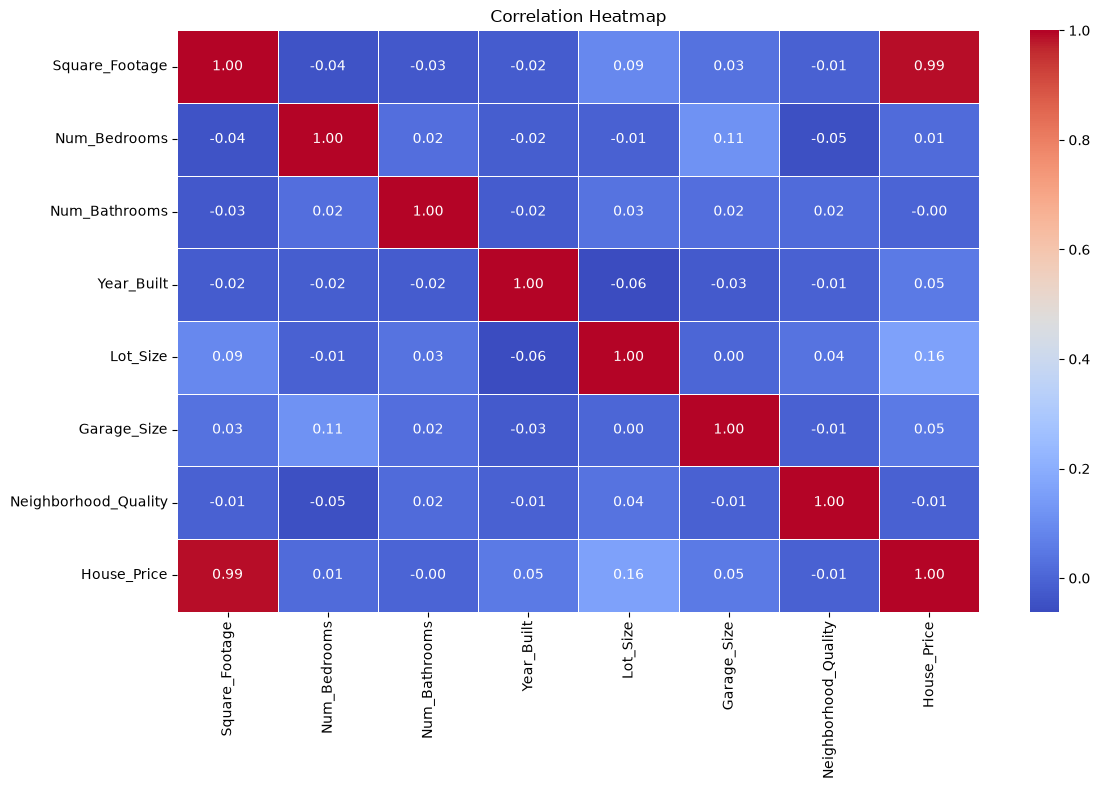

In [111]:
numeric_df = df_clean.select_dtypes(include="number")
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("correlation_heatmap")
plt.show()

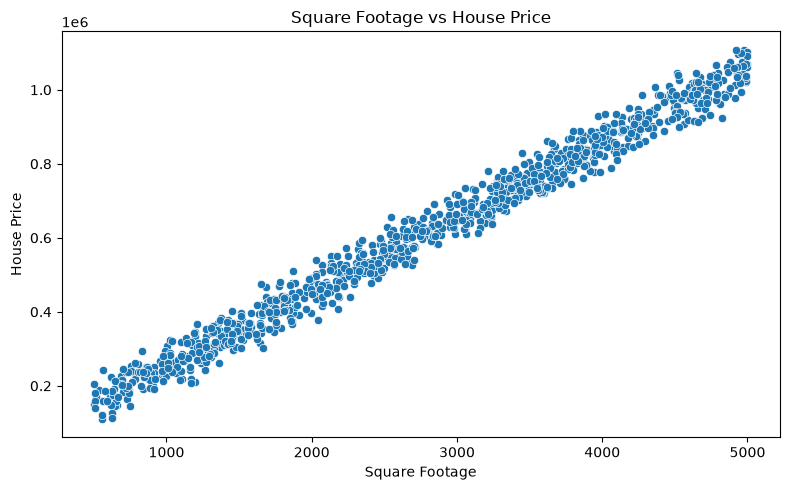

In [112]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="Square_Footage",
    y="House_Price"
)

plt.title("Square Footage vs House Price")
plt.xlabel("Square Footage")
plt.ylabel("House Price")
plt.tight_layout()
plt.show()

In [113]:
df_clean.head()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360.0,2.0,1.0,1981.0,0.599637,0.0,5.0,2.623829e+05
1,4272.0,3.0,3.0,2016.0,4.753014,1.0,6.0,9.852609e+05
2,3592.0,1.0,2.0,2016.0,3.634823,0.0,9.0,7.779774e+05
3,966.0,1.0,2.0,1977.0,2.730667,1.0,8.0,2.296989e+05
4,4926.0,2.0,1.0,1993.0,4.699073,0.0,8.0,1.041741e+06


---
### Feature Engineering
---

In [114]:
from sklearn.preprocessing import StandardScaler
cols = ["Square_Footage", "Num_Bedrooms", "Num_Bathrooms", "Year_Built", "Garage_Size", "Lot_Size", "Neighborhood_Quality"]
scaler = StandardScaler()
df_clean[cols] = scaler.fit_transform(df_clean[cols])
df_clean.head()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,-1.159803,-0.693836,-1.186699,-0.269122,-1.679278,-1.254658,-0.213126,2.623829e+05
1,1.160724,0.007008,1.252559,1.428045,1.522390,-0.027008,0.133420,9.852609e+05
2,0.618843,-1.394681,0.032930,1.428045,0.660422,-1.254658,1.173060,7.779774e+05
3,-1.473776,-1.394681,0.032930,-0.463084,-0.036555,-0.027008,0.826514,2.296989e+05
4,1.681887,-0.693836,-1.186699,0.312764,1.480809,-1.254658,0.826514,1.041741e+06


In [115]:
#Pearson Correlation  Calculation
from scipy.stats import pearsonr

selected_features = [
    "Square_Footage", "Num_Bedrooms", "Num_Bathrooms", "Year_Built", "Garage_Size", "Lot_Size", "Neighborhood_Quality"
]

correlations = {
    feature: pearsonr(df_clean[feature], df_clean['House_Price'])[0]
    for feature in selected_features
}
correlation_df = pd.DataFrame(list(correlations.items()), columns=['Feature', 'Pearson Correlation'])
correlation_df.sort_values(by='Pearson Correlation', ascending=False)

,Feature,Pearson Correlation
0,Square_Footage,0.991261
5,Lot_Size,0.160412
4,Garage_Size,0.052133
3,Year_Built,0.051967
1,Num_Bedrooms,0.014633
2,Num_Bathrooms,-0.001862
6,Neighborhood_Quality,-0.007770


In [116]:
final_df = df_clean[["Square_Footage", "Num_Bedrooms", "Year_Built", "Garage_Size", "Lot_Size","House_Price","Num_Bathrooms","Neighborhood_Quality"]]
final_df

,Square_Footage,Num_Bedrooms,Year_Built,Garage_Size,Lot_Size,House_Price,Num_Bathrooms,Neighborhood_Quality
0,-1.159803,-0.693836,-0.269122,-1.254658,-1.679278,2.623829e+05,-1.186699,-0.213126
1,1.160724,0.007008,1.428045,-0.027008,1.522390,9.852609e+05,1.252559,0.133420
2,0.618843,-1.394681,1.428045,-1.254658,0.660422,7.779774e+05,0.032930,1.173060
3,-1.473776,-1.394681,-0.463084,-0.027008,-0.036555,2.296989e+05,0.032930,0.826514
4,1.681887,-0.693836,0.312764,-1.254658,1.480809,1.041741e+06,-1.186699,0.826514
...,...,...,...,...,...,...,...,...
995,0.355074,0.707853,-0.414594,1.200641,-0.472519,7.014940e+05,-1.186699,1.519607
996,0.289730,-1.394681,0.603707,-0.027008,0.153428,6.837232e+05,0.032930,1.519607
997,-0.166885,0.707853,-1.190442,-1.254658,0.984371,5.720240e+05,0.032930,-1.252766
998,1.520119,1.408698,-1.772328,-1.254658,-0.653046,9.648653e+05,0.032930,0.479967


In [117]:
X = final_df.drop('House_Price', axis=1)
y = final_df['House_Price']

In [118]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [119]:
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[250366.58, 14589.83, 20489.32,..., 19310.12, 6730.27, 332.04]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['Square_Footage','Num_Bedrooms','Year_Built',...,'Lot_Size', 'Num_Bathrooms','Neighborhood_Quality']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6.189e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [120]:
y_pred = model.predict(X_test)

In [121]:
r2 = r2_score(y_test,y_pred)
r2

0.9984263636823413

In [122]:
n = X_test.shape[0]
p = X_test.shape[1]
adjusted_r2 = 1 - ((1- r2) * (n-1) / (n - p - 1))
adjusted_r2

0.9983689915249266